## Import libraries

In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_excel(r"C:\Users\marwan\Desktop\Python Route\Assignments\Trees\Dry_Bean_Dataset.xlsx")

In [3]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df.shape

(13611, 17)

## Separate Features and Target

In [5]:
X = df.drop("Class", axis=1)
y = df["Class"]

### Split the data

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (10888, 16)
X_test: (2723, 16)
y_train: (10888,)
y_test: (2723,)


## 1. Decision Tree 

In [8]:
features_5 = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "roundness"
]

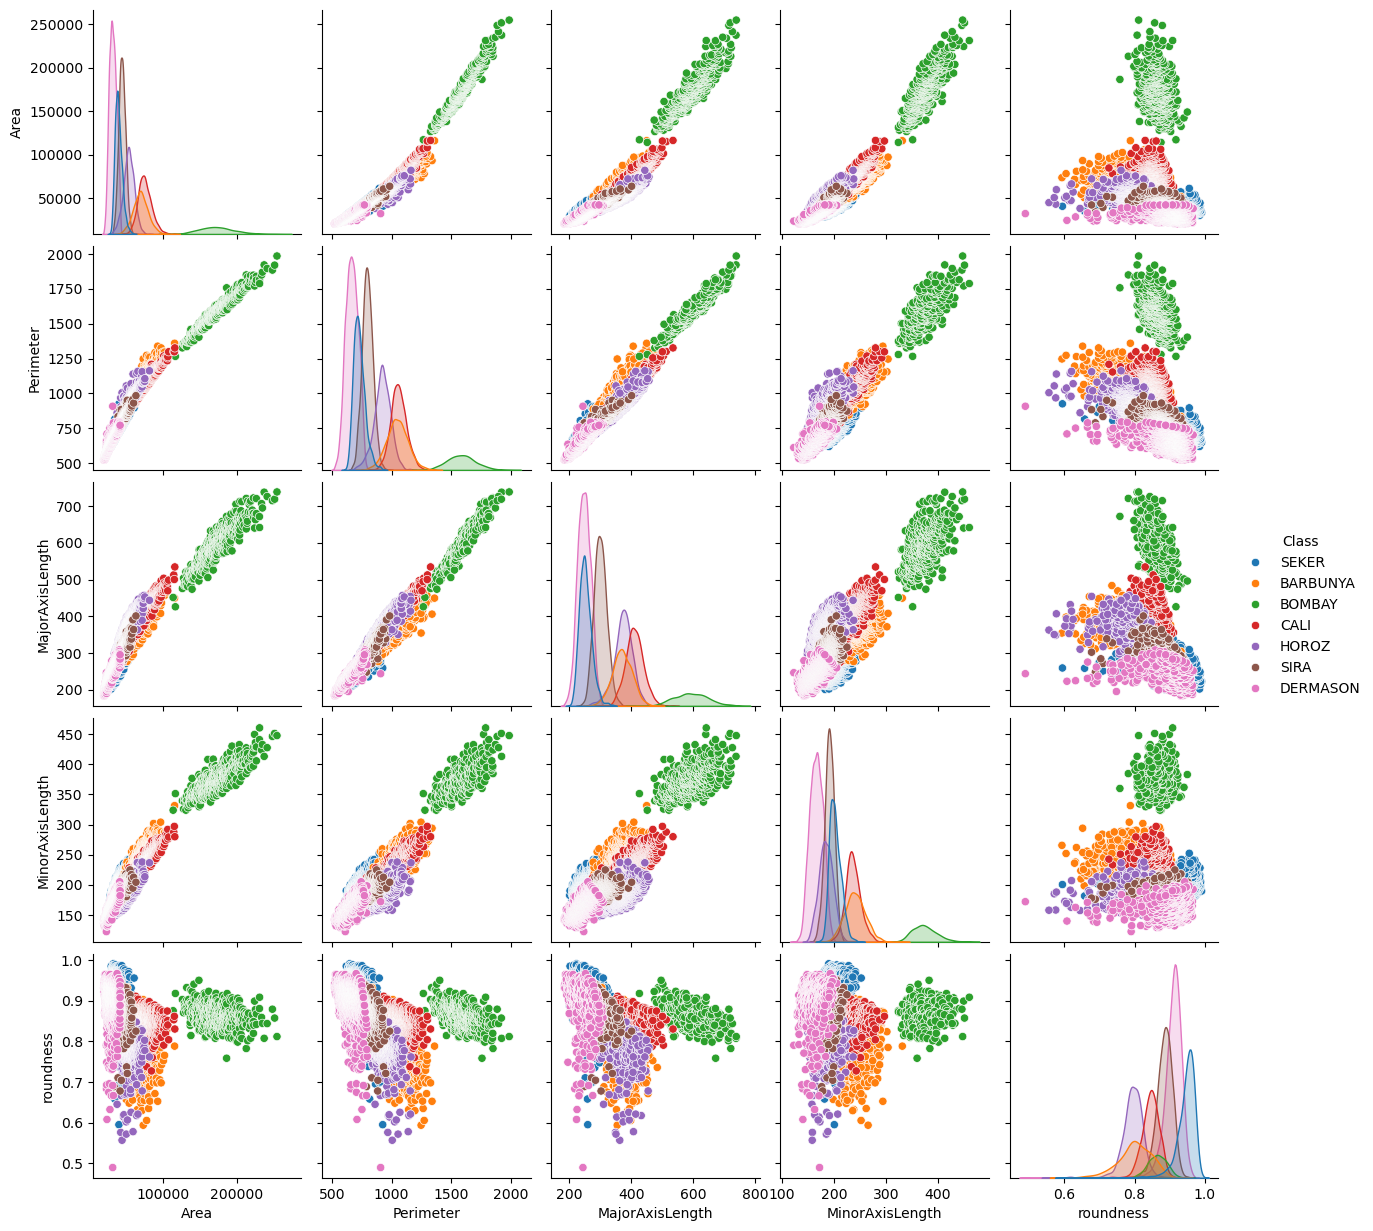

In [11]:
# Scatterplot Matrix

import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    df[features_5 + ["Class"]],
    hue="Class"
)

plt.show()

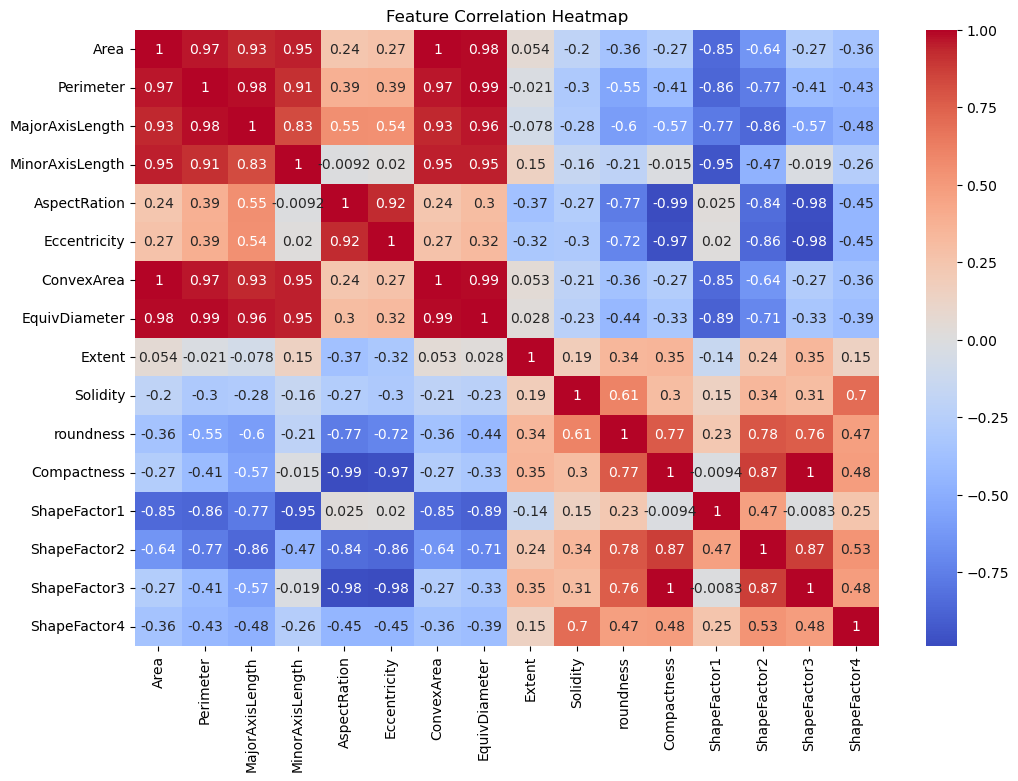

In [12]:
# Correlation Heatmap

plt.figure(figsize=(12, 8))

correlation = X.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

## Data Cleaning

In [13]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [14]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

In [17]:
# Encode Class  

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)


['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


In [20]:
# Check Duplicates
print("Duplicates:", df.duplicated().sum())

Duplicates: 68


In [21]:
df = df.drop_duplicates()

In [24]:
print(df.duplicated().sum())

0


In [25]:
X = df.drop("Class", axis=1)

y = df["Class"]

y_encoded = label_encoder.fit_transform(y)

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded)

## Decision Tree

In [29]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


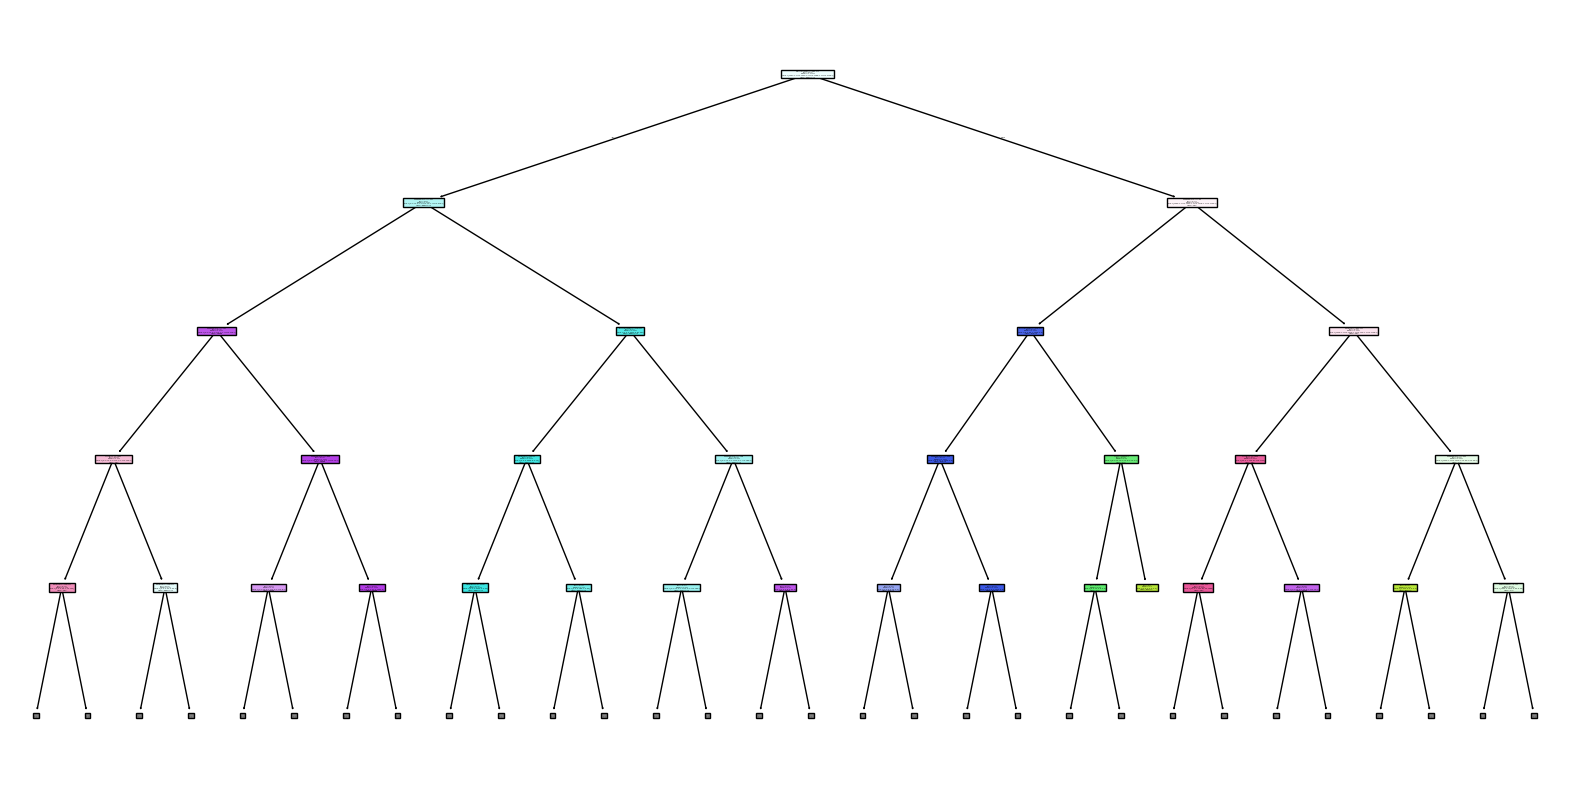

In [30]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    max_depth=4,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True
)

plt.show()

## Top 3 Splitting Nodes

In [31]:
tree = dt.tree_

for i in range(3):
    feature = X.columns[tree.feature[i]]
    threshold = tree.threshold[i]

    print("Node:", i)
    print("Feature:", feature)
    print("Threshold:", threshold)
    print()

Node: 0
Feature: MajorAxisLength
Threshold: 280.7041931152344

Node: 1
Feature: ShapeFactor1
Threshold: 0.006820928305387497

Node: 2
Feature: ShapeFactor3
Threshold: 0.7274537682533264



In [34]:
# Training Accuracy

train_accuracy = dt.score(X_train, y_train)

print("Training Accuracy:", train_accuracy)

Training Accuracy: 1.0


In [35]:
## Test Accuracy

test_accuracy = dt.score(X_test, y_test)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.896640826873385


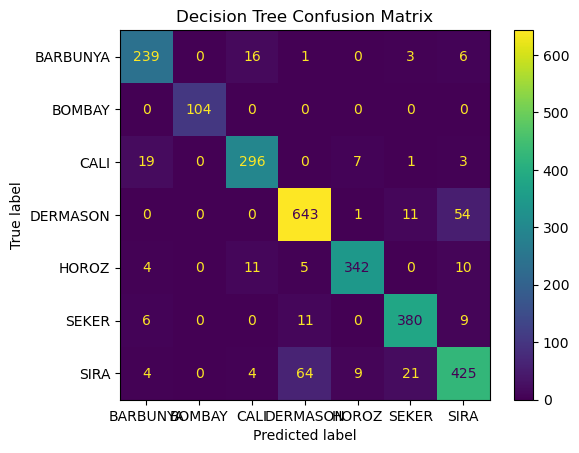

In [36]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = dt.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("Decision Tree Confusion Matrix")
plt.show()

## Different max_depth

In [39]:
from sklearn.metrics import accuracy_score

results = []

criteria = ["gini", "entropy"]
depths = [3, 5, 10, 15]

for criterion in criteria:
    for depth in depths:

        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        results.append({
            "Criterion": criterion,
            "Max Depth": depth,
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Test Accuracy": accuracy_score(y_test, test_pred),
            "Tree Depth": model.get_depth()
        })

In [42]:
results_df = pd.DataFrame(results)
results_df

,Criterion,Max Depth,Train Accuracy,Test Accuracy,Tree Depth
0,gini,3,0.777552,0.770026,3
1,gini,5,0.890807,0.874862,5
2,gini,10,0.965479,0.903654,10
3,gini,15,0.993447,0.901440,15
4,entropy,3,0.808012,0.799557,3
5,entropy,5,0.903175,0.887781,5
6,entropy,10,0.963541,0.894426,10
7,entropy,15,0.996308,0.891473,15


## ccp_alpha

In [43]:
temp_tree = DecisionTreeClassifier(random_state=42)

path = temp_tree.cost_complexity_pruning_path(
    X_train,
    y_train
)

alphas = path.ccp_alphas

In [44]:
alpha_results = []

for alpha in alphas:

    model = DecisionTreeClassifier(
        ccp_alpha=alpha,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    alpha_results.append({
        "Alpha": alpha,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Tree Depth": model.get_depth()
    })

alpha_df = pd.DataFrame(alpha_results)

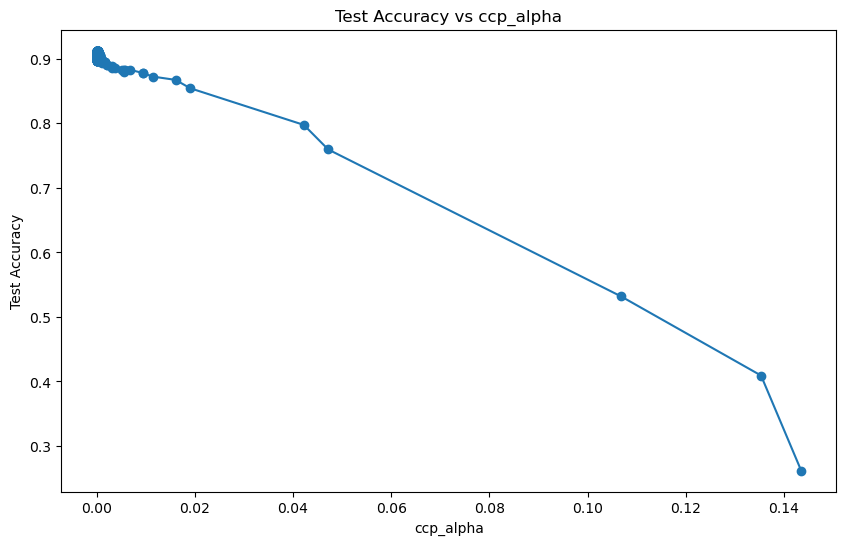

In [45]:
# plot Test Accuracy vs Alpha
plt.figure(figsize=(10, 6))

plt.plot(
    alpha_df["Alpha"],
    alpha_df["Test Accuracy"],
    marker="o"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy vs ccp_alpha")

plt.show()

In [46]:
# Find Best Alpha
best_alpha_row = alpha_df.loc[
    alpha_df["Test Accuracy"].idxmax()
]

print(best_alpha_row)

Alpha              0.000169
Train Accuracy     0.972402
Test Accuracy      0.912514
Tree Depth        16.000000
Name: 205, dtype: float64


## 2- Bagging

In [47]:
from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [50]:
svm = SVC()

bagging_svm = BaggingClassifier(
    estimator=svm,
    n_estimators=10,
    random_state=42
)

In [54]:
# Train
bagging_svm.fit(X_train, y_train)

,estimator,SVC()
,n_estimators,10
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,42
,verbose,0


In [55]:
# Predict
y_pred_svm = bagging_svm.predict(X_test)

In [56]:
# Accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("Bagging SVM Accuracy:", svm_accuracy)

Bagging SVM Accuracy: 0.636766334440753


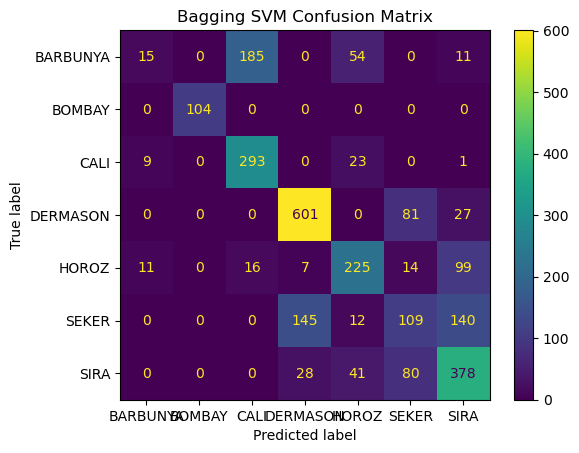

In [58]:
# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm,display_labels=label_encoder.classes_)

disp.plot()

plt.title("Bagging SVM Confusion Matrix")
plt.show()

In [59]:
# Create Decision Tree
dt_base = DecisionTreeClassifier(random_state=42)

In [60]:
# Create Bagging
bagging_dt = BaggingClassifier(
    estimator=dt_base,
    n_estimators=10,
    random_state=42
)

In [61]:
# train
bagging_dt.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,n_estimators,10
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,42
,verbose,0


In [62]:
# Predict
y_pred_dt = bagging_dt.predict(X_test)

In [63]:
# Accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Bagging Decision Tree Accuracy:", dt_accuracy)

Bagging Decision Tree Accuracy: 0.9136212624584718


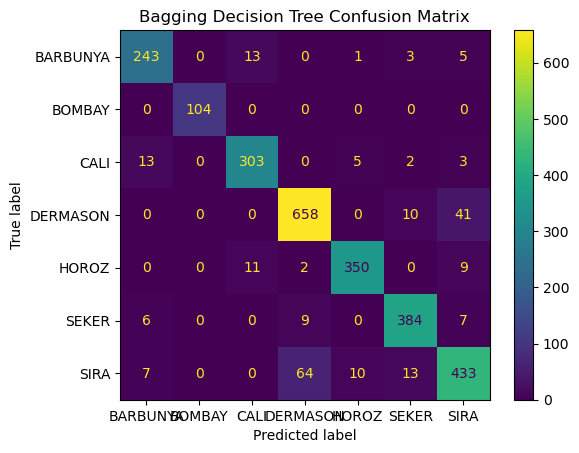

In [64]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("Bagging Decision Tree Confusion Matrix")
plt.show()

In [66]:
comparison = pd.DataFrame({
    "Model": ["Bagging SVM", "Bagging Decision Tree"],
    "Test Accuracy": [svm_accuracy, dt_accuracy]
})

comparison

,Model,Test Accuracy
0,Bagging SVM,0.636766
1,Bagging Decision Tree,0.913621


## Random Forest

In [67]:
from sklearn.ensemble import RandomForestClassifier

In [68]:
rf = RandomForestClassifier(
    random_state=42
)

In [69]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [70]:
y_pred_rf = rf.predict(X_test)

In [71]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9198966408268734


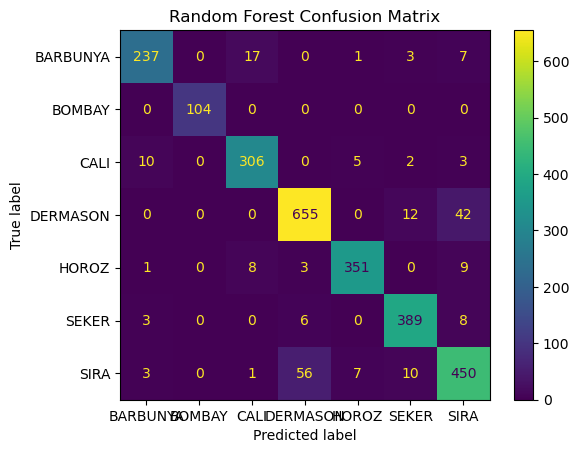

In [72]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

### Fine-Tune Number of Estimators

In [73]:
n_results = []

n_values = [10, 50, 100, 150, 200]

for n in n_values:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    n_results.append({
        "n_estimators": n,
        "Accuracy": accuracy
    })

n_results_df = pd.DataFrame(n_results)

print(n_results_df)

   n_estimators  Accuracy
0            10  0.914360
1            50  0.917682
2           100  0.919897
3           150  0.918789
4           200  0.919528


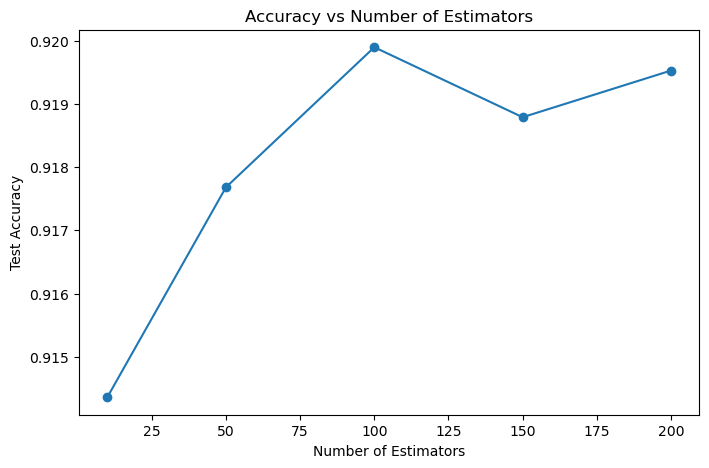

In [74]:
# Plot Accuracy vs Number of Trees
plt.figure(figsize=(8, 5))

plt.plot(
    n_results_df["n_estimators"],
    n_results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Number of Estimators")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Number of Estimators")

plt.show()

In [75]:
# max_features
feature_values = ["sqrt", "log2", 5]

feature_results = []

for value in feature_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_features=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    feature_results.append({
        "max_features": value,
        "Accuracy": accuracy
    })

feature_results_df = pd.DataFrame(feature_results)

print(feature_results_df)

  max_features  Accuracy
0         sqrt  0.919897
1         log2  0.919897
2            5  0.918051


In [76]:
best_rf = RandomForestClassifier(
    n_estimators=150,
    max_features="sqrt",
    random_state=42
)

best_rf.fit(X_train, y_train)

,n_estimators,150
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


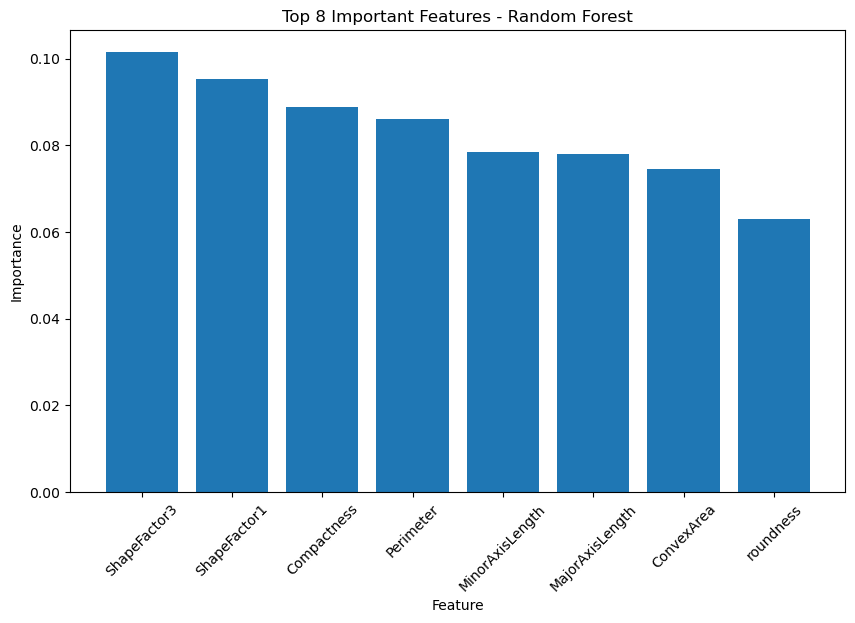

In [78]:
# Top 8 Important Features
top_8 = importance.head(8)

plt.figure(figsize=(10, 6))

plt.bar(
    top_8["Feature"],
    top_8["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Top 8 Important Features - Random Forest")

plt.xticks(rotation=45)

plt.show()

## 3. Boosting 

In [79]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [80]:
# n_estimators
gb_results = []

n_values = [10, 50, 100, 200]

for n in n_values:

    gb = GradientBoostingClassifier(
        n_estimators=n,
        random_state=42
    )

    gb.fit(X_train, y_train)

    y_pred = gb.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    gb_results.append({
        "n_estimators": n,
        "Accuracy": accuracy
    })

gb_results_df = pd.DataFrame(gb_results)

print(gb_results_df)

   n_estimators  Accuracy
0            10  0.906608
1            50  0.916574
2           100  0.917682
3           200  0.915098


In [81]:
# best n_estimators
best_n = gb_results_df.loc[
    gb_results_df["Accuracy"].idxmax(),
    "n_estimators"
]

print("Best n_estimators:", best_n)

Best n_estimators: 100


In [82]:
# Tune learning_rate
lr_results = []

learning_rates = [0.1, 0.3, 0.5, 0.9]

for lr in learning_rates:

    gb = GradientBoostingClassifier(
        n_estimators=best_n,
        learning_rate=lr,
        random_state=42
    )

    gb.fit(X_train, y_train)

    y_pred = gb.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    lr_results.append({
        "learning_rate": lr,
        "Accuracy": accuracy
    })

lr_results_df = pd.DataFrame(lr_results)

print(lr_results_df)

   learning_rate  Accuracy
0            0.1  0.917682
1            0.3  0.911776
2            0.5  0.911406
3            0.9  0.906238


In [83]:
# best learning_rate
best_lr = lr_results_df.loc[
    lr_results_df["Accuracy"].idxmax(),
    "learning_rate"
]

print("Best learning rate:", best_lr)

Best learning rate: 0.1


In [84]:
# Best Gradient Boosting Model
best_gb = GradientBoostingClassifier(
    n_estimators=best_n,
    learning_rate=best_lr,
    random_state=42
)

best_gb.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,np.float64(0.1)
,n_estimators,np.int64(100)
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [85]:
gb_pred = best_gb.predict(X_test)

gb_accuracy = accuracy_score(y_test, gb_pred)

print("Best Gradient Boosting Accuracy:", gb_accuracy)

Best Gradient Boosting Accuracy: 0.9176818014027316


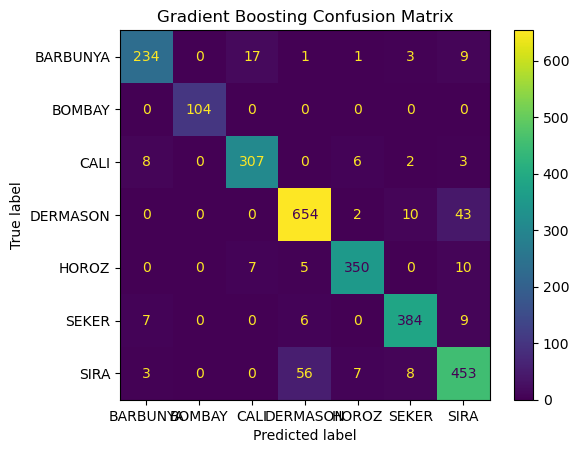

In [86]:
cm_gb = confusion_matrix(y_test, gb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [87]:
# Learning Curve
train_acc = []
test_acc = []

estimator_values = [10, 20, 40, 60, 80, 100, 150, 200]

for n in estimator_values:

    model = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=best_lr,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

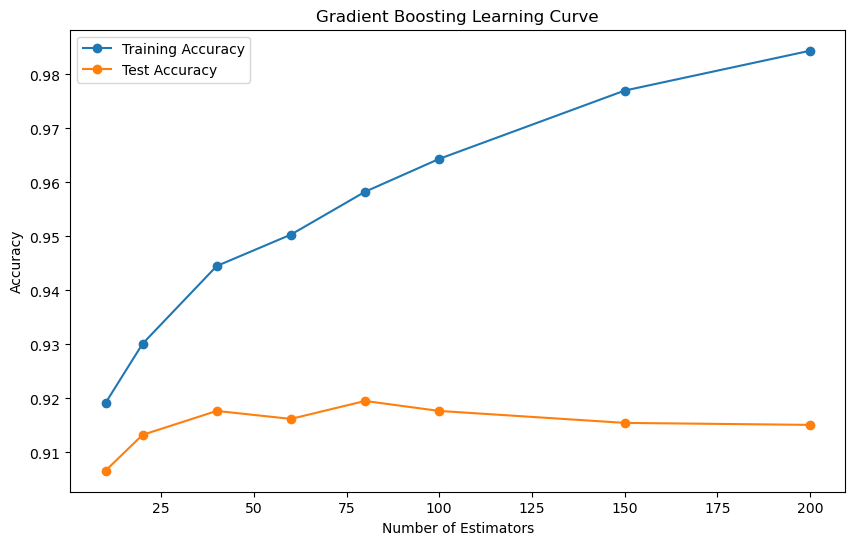

In [88]:
plt.figure(figsize=(10, 6))

plt.plot(
    estimator_values,
    train_acc,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    estimator_values,
    test_acc,
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting Learning Curve")

plt.legend()
plt.show()

In [93]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb = XGBClassifier(
    n_estimators=best_n,
    learning_rate=best_lr,
    random_state=42
)

In [ ]:
xgb.fit(X_train, y_train)

In [ ]:
xgb_pred = xgb.predict(X_test)

In [ ]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

In [ ]:
cm_xgb = confusion_matrix(y_test, xgb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("XGBoost Confusion Matrix")
plt.show()

In [ ]:
subsample_values = [0.6, 0.8, 1.0]

subsample_results = []

for value in subsample_values:

    model = XGBClassifier(
        n_estimators=best_n,
        learning_rate=best_lr,
        subsample=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    subsample_results.append({
        "subsample": value,
        "Accuracy": accuracy
    })

subsample_df = pd.DataFrame(subsample_results)

print(subsample_df)

## PCA

In [ ]:
dt_pred = dt.predict(X_test)

bag_svm_pred = bagging_svm.predict(X_test)

bag_dt_pred = bagging_dt.predict(X_test)

rf_pred = best_rf.predict(X_test)

gb_pred = best_gb.predict(X_test)

xgb_pred = xgb.predict(X_test)

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score
)

In [ ]:
models_predictions = {
    "Decision Tree": dt_pred,
    "Bagged SVM": bag_svm_pred,
    "Bagged DT": bag_dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred,
    "XGBoost": xgb_pred
}

In [ ]:
results = []

for name, predictions in models_predictions.items():

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "F1-Score": f1_score(
            y_test,
            predictions,
            average="weighted"
        )
    })

metrics_df = pd.DataFrame(results)

print(metrics_df)

In [ ]:
metrics = ["Precision", "Recall", "Accuracy", "F1-Score"]

for metric in metrics:

    best_model = metrics_df.loc[
        metrics_df[metric].idxmax(),
        "Model"
    ]

    worst_model = metrics_df.loc[
        metrics_df[metric].idxmin(),
        "Model"
    ]

    print(metric)
    print("Best:", best_model)
    print("Worst:", worst_model)
    print()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance Ratio per Component")

plt.show()

In [ ]:
pca_95 = PCA(
    n_components=n_components_95
)

X_train_pca95 = pca_95.fit_transform(X_train_scaled)

X_test_pca95 = pca_95.transform(X_test_scaled)

In [ ]:
pca_model = XGBClassifier(
    n_estimators=best_n,
    learning_rate=best_lr,
    random_state=42
)

pca_model.fit(
    X_train_pca95,
    y_train
)

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

In [ ]:
top_6_features = importance.head(6)["Feature"].tolist()

print("Top 6 Features:")
print(top_6_features)

In [ ]:
X_train_selected = X_train[top_6_features]

X_test_selected = X_test[top_6_features]

In [ ]:
feature_model = XGBClassifier(
    n_estimators=best_n,
    learning_rate=best_lr,
    random_state=42
)

feature_model.fit(
    X_train_selected,
    y_train
)

In [ ]:
top_6 = importance.head(6)

plt.figure(figsize=(10, 6))

plt.bar(
    top_6["Feature"],
    top_6["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Top 6 Important Features")

plt.xticks(rotation=45)

plt.show()

In [ ]:
pca_pred = pca_model.predict(X_test_pca95)

In [ ]:
feature_pred = feature_model.predict(X_test_selected)

In [ ]:
pca_results = {
    "Precision": precision_score(
        y_test,
        pca_pred,
        average="weighted"
    ),
    "Recall": recall_score(
        y_test,
        pca_pred,
        average="weighted"
    ),
    "Accuracy": accuracy_score(
        y_test,
        pca_pred
    ),
    "F1-Score": f1_score(
        y_test,
        pca_pred,
        average="weighted"
    )
}

print("PCA Model")
print(pca_results)